# Exploratory Data Analysis

## Objective

Analyze the cleaned retail transaction dataset to identify patterns, trends, relationships, anomalies, and business insights that can support data-driven decision making.

The analysis will focus on:

- Sales and profitability trends
- Product and category performance
- Regional performance
- Customer and transaction patterns
- Sales channel performance
- Payment method distribution
- Order status analysis
- Relationships between key numerical variables
- Identification of potential business opportunities and risks

## Analysis Approach

The EDA will combine:

- Univariate analysis
- Bivariate analysis
- Multivariate analysis
- Statistical summaries
- Distribution analysis
- Correlation analysis
- Business-focused visualizations

The objective is not only to visualize the data, but to translate analytical findings into meaningful business insights.

In [1]:
from unittest.mock import inplace

import numpy as np
import pandas as pd

In [2]:
df=pd.read_csv('../data/processed/sales_cleaned.csv')
df

,order_id,order_date,customer_id,customer_name,region,state,city,category,subcategory,product,quantity,unit_price,discount,sales,cost,profit,payment_method,sales_channel,order_status
0,ORD-003886,2025-10-31 20:49:55,11279,Aarav Patel,North,Delhi,Delhi,Electronics,Smartphones,Nova X5,1,21280.44,0.00,21280.44,16087.18,5193.26,Debit Card,Online,Delivered
1,ORD-039073,2025-03-08 04:49:07,13949,Priya Mehta,East,Bihar,Patna,Electronics,Smartphones,ZenPhone Lite,1,14888.11,0.20,11910.49,10801.13,1109.35,Upi,Store,Delivered
2,ORD-034360,2024-03-19 11:48:17,10252,Priya Reddy,North,Uttarakhand,Dehradun,Electronics,Smartphones,PixelMax A2,2,18560.63,0.05,35265.20,23705.16,11560.04,Credit Card,Online,Delivered
3,ORD-010240,2024-11-07 00:00:00,12307,Ishaan Mehta,South,Kerala,Kochi,Home & Kitchen,Kitchenware,Storage Set,2,1522.45,0.05,2892.66,2117.20,775.46,Debit Card,Online,Delivered
4,ORD-035487,2024-09-15 00:27:26,10731,Ananya Reddy,South,Kerala,Kochi,Furniture,Office,Study Desk,1,9309.10,0.05,8843.65,7120.30,1723.34,Cash on Delivery,Online,Cancelled
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49970,ORD-011285,2025-10-28 12:27:58,12688,Diya Kumar,West,Gujarat,Surat,Electronics,Smartphones,PixelMax A2,4,18763.34,0.10,67548.02,48384.46,19163.56,Upi,Store,Delivered
49971,ORD-044733,2024-07-27 06:46:51,11008,Aarav Nair,West,Maharashtra,Mumbai,Furniture,Home,TV Unit,1,11557.39,0.25,8668.04,8742.12,-74.07,Debit Card,Online,Delivered
49972,ORD-038159,2025-11-07 17:11:41,12272,Isha Sharma,East,West Bengal,Kolkata,Home & Kitchen,Kitchenware,Cookware Set,5,3362.06,0.10,15129.27,10392.20,4737.07,Debit Card,Online,Delivered
49973,ORD-000861,2024-04-25 15:26:49,10795,Ishaan Patel,East,Odisha,Bhubaneswar,Electronics,Accessories,Wireless Earbuds,1,2956.79,0.05,2808.95,2128.56,680.39,Upi,Online,Delivered


In [3]:
df.shape

(49975, 19)

In [4]:
df.head()

,order_id,order_date,customer_id,customer_name,region,state,city,category,subcategory,product,quantity,unit_price,discount,sales,cost,profit,payment_method,sales_channel,order_status
0,ORD-003886,2025-10-31 20:49:55,11279,Aarav Patel,North,Delhi,Delhi,Electronics,Smartphones,Nova X5,1,21280.44,0.00,21280.44,16087.18,5193.26,Debit Card,Online,Delivered
1,ORD-039073,2025-03-08 04:49:07,13949,Priya Mehta,East,Bihar,Patna,Electronics,Smartphones,ZenPhone Lite,1,14888.11,0.20,11910.49,10801.13,1109.35,Upi,Store,Delivered
2,ORD-034360,2024-03-19 11:48:17,10252,Priya Reddy,North,Uttarakhand,Dehradun,Electronics,Smartphones,PixelMax A2,2,18560.63,0.05,35265.20,23705.16,11560.04,Credit Card,Online,Delivered
3,ORD-010240,2024-11-07 00:00:00,12307,Ishaan Mehta,South,Kerala,Kochi,Home & Kitchen,Kitchenware,Storage Set,2,1522.45,0.05,2892.66,2117.20,775.46,Debit Card,Online,Delivered
4,ORD-035487,2024-09-15 00:27:26,10731,Ananya Reddy,South,Kerala,Kochi,Furniture,Office,Study Desk,1,9309.10,0.05,8843.65,7120.30,1723.34,Cash on Delivery,Online,Cancelled


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 49975 entries, 0 to 49974
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        49975 non-null  str    
 1   order_date      49975 non-null  str    
 2   customer_id     49975 non-null  int64  
 3   customer_name   49975 non-null  str    
 4   region          49975 non-null  str    
 5   state           49975 non-null  str    
 6   city            49975 non-null  str    
 7   category        49975 non-null  str    
 8   subcategory     49975 non-null  str    
 9   product         49975 non-null  str    
 10  quantity        49975 non-null  int64  
 11  unit_price      49975 non-null  float64
 12  discount        49975 non-null  float64
 13  sales           49975 non-null  float64
 14  cost            49975 non-null  float64
 15  profit          49975 non-null  float64
 16  payment_method  49975 non-null  str    
 17  sales_channel   49975 non-null  str    
 1

##  Numerical Analysis

In [6]:
df.describe()

,customer_id,quantity,unit_price,discount,sales,cost,profit
count,49975.000000,49975.000000,49975.000000,49975.000000,49975.00000,49975.000000,49975.000000
mean,12997.441461,2.448164,5312.103056,0.096230,11736.04691,8704.609481,3031.437434
std,1734.565943,1.526342,5795.368440,0.070106,16472.11125,12231.082457,4808.230636
min,10001.000000,1.000000,388.590000,0.000000,309.06000,252.200000,-6854.310000
25%,11493.000000,1.000000,1615.875000,0.050000,2612.64500,1942.910000,558.265000
50%,12994.000000,2.000000,2756.110000,0.100000,5560.02000,4147.650000,1323.580000
75%,14502.000000,3.000000,6531.015000,0.150000,13141.86000,9698.525000,3253.965000
max,16000.000000,30.000000,25293.510000,0.250000,144685.39000,102743.990000,63266.140000


In [7]:
df[['quantity', 'unit_price', 'discount', 'sales', 'cost', 'profit']].describe()

,quantity,unit_price,discount,sales,cost,profit
count,49975.000000,49975.000000,49975.000000,49975.00000,49975.000000,49975.000000
mean,2.448164,5312.103056,0.096230,11736.04691,8704.609481,3031.437434
std,1.526342,5795.368440,0.070106,16472.11125,12231.082457,4808.230636
min,1.000000,388.590000,0.000000,309.06000,252.200000,-6854.310000
25%,1.000000,1615.875000,0.050000,2612.64500,1942.910000,558.265000
50%,2.000000,2756.110000,0.100000,5560.02000,4147.650000,1323.580000
75%,3.000000,6531.015000,0.150000,13141.86000,9698.525000,3253.965000
max,30.000000,25293.510000,0.250000,144685.39000,102743.990000,63266.140000


In [8]:
import seaborn as sns

<Axes: xlabel='sales', ylabel='Count'>

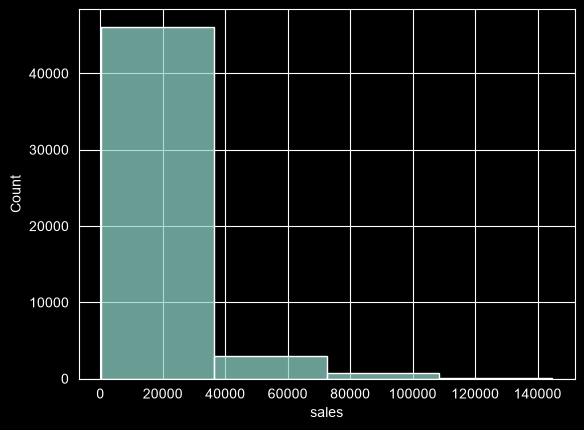

In [9]:
sns.histplot(x='sales',data=df,bins=4)

### Sales Distribution Insight

The Sales distribution is right-skewed. Most transactions are concentrated at lower sales values, while a relatively small number of high-value transactions create a long right tail.

This indicates the presence of high-value transactions that may require further investigation as potential outliers or legitimate bulk/high-value orders.

<Axes: xlabel='sales', ylabel='Count'>

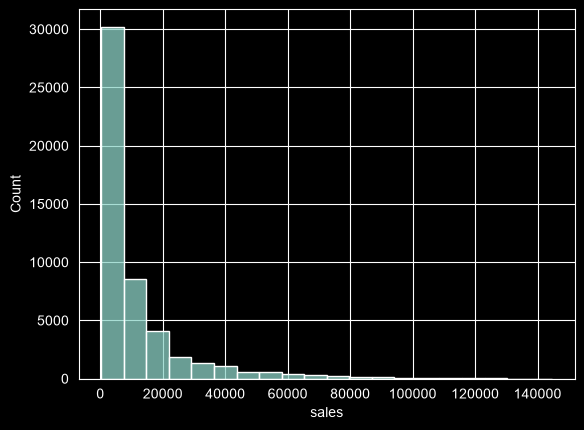

In [10]:
sns.histplot(x='sales',data=df,bins=20)

<Axes: xlabel='quantity', ylabel='Count'>

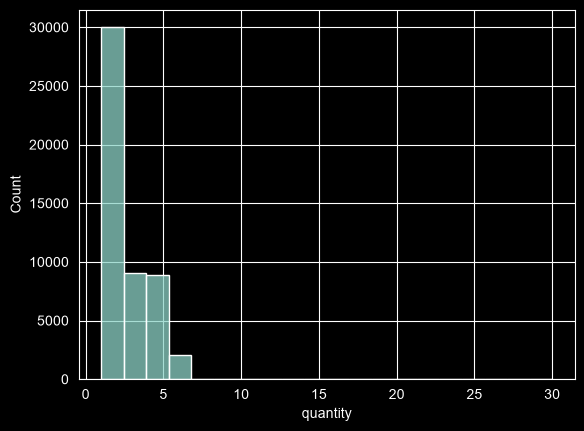

In [11]:
sns.histplot(x='quantity',data=df,bins=20)

### Quantity Distribution Insight

The Quantity distribution is right-skewed. Most transactions involve a small number of units, primarily between 1 and 5 units, while a small number of transactions have substantially higher quantities.

The quantity value of 30 appears unusually high compared with the majority of transactions and should be investigated to determine whether it represents legitimate bulk orders or a potential data anomaly.

<Axes: xlabel='discount', ylabel='Count'>

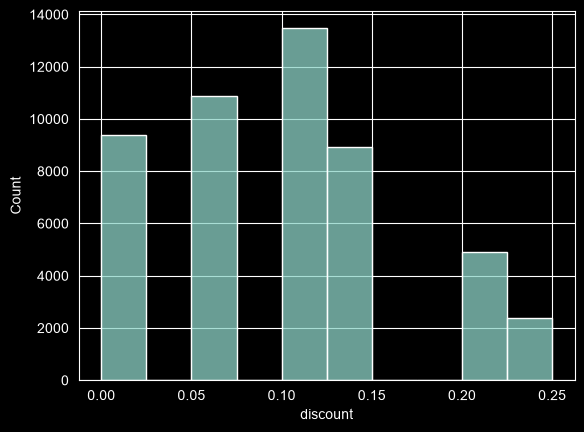

In [12]:
sns.histplot(x='discount',data=df,bins=10)

### Discount Distribution Insight

The Discount distribution is concentrated around a small number of predefined discount levels, particularly 5%, 10%, and 15%.

The 10% discount level has the highest frequency, while higher discount levels such as 20% and 25% occur less frequently.

Unlike Sales and Quantity, the Discount distribution does not show a strong continuous right or left skew. Instead, it reflects a discrete, multi-level discount structure.

<Axes: xlabel='profit', ylabel='Count'>

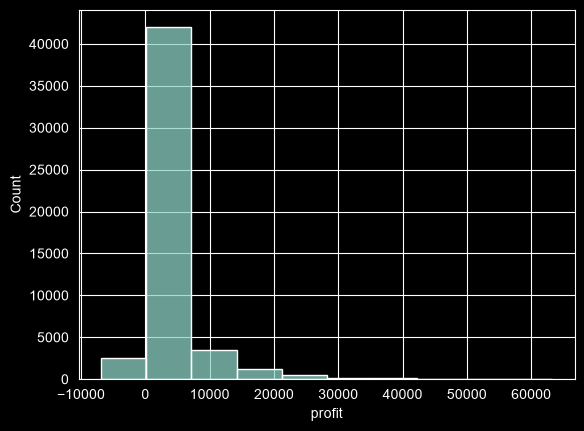

In [13]:
sns.histplot(x='profit',data=df,bins=10)

### Profit Distribution Insight

The Profit distribution is strongly right-skewed. Most transactions generate moderate positive profits, while a smaller number of transactions have substantially higher profits, creating a long right tail.

The distribution also contains negative-profit transactions, indicating cases where transaction costs exceed sales. These transactions should be investigated from a business perspective rather than automatically treated as data errors.

<Axes: xlabel='unit_price', ylabel='Count'>

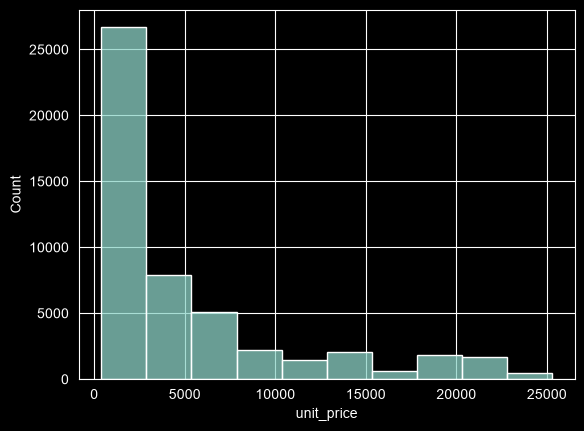

In [14]:
sns.histplot(x='unit_price',data=df,bins=10)

### Unit Price Distribution Insight

The Unit Price distribution is right-skewed. Most transactions involve products with relatively lower unit prices, while a smaller number of transactions involve significantly higher-priced products, creating a long right tail.

The high unit-price transactions should be considered when analyzing product and category performance, as they may have a substantial influence on overall sales.

##  Categorical Analysis

<Axes: xlabel='category', ylabel='count'>

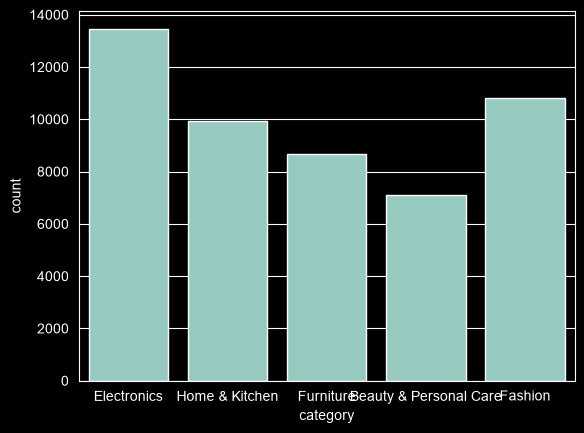

In [15]:
sns.countplot(x='category',data=df)

### Category Distribution Insight

Electronics has the highest transaction volume among the product categories, while Beauty & Personal Care has the lowest transaction volume.

The distribution shows that transaction volume varies across categories. However, transaction count alone does not indicate overall business performance, so category-level Sales and Profit should be analyzed separately.

<Axes: xlabel='region', ylabel='count'>

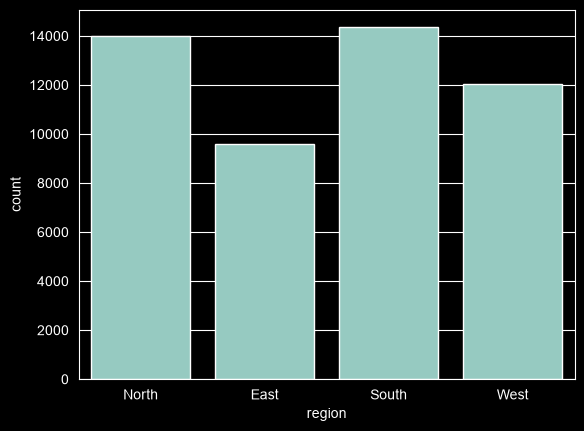

In [16]:
sns.countplot(x='region',data=df)

### Region Distribution Insight

The South region has the highest transaction volume, followed closely by the North region. The East region has the lowest transaction volume, while the West region falls between the two.

Transaction volume provides an understanding of order distribution across regions, but it does not by itself indicate regional revenue or profitability. Regional Sales and Profit should be analyzed separately.

<Axes: xlabel='sales_channel', ylabel='count'>

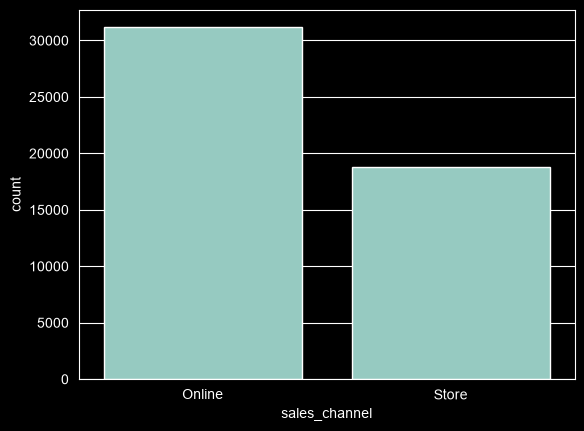

In [17]:
sns.countplot(x='sales_channel',data=df)

### Sales Channel Distribution Insight

The Online channel has a higher transaction volume than the Store channel, indicating that a larger proportion of transactions are generated through online sales.

However, transaction volume alone does not determine channel performance. Sales and Profit should be compared between Online and Store channels to evaluate their financial contribution.

<Axes: xlabel='payment_method', ylabel='count'>

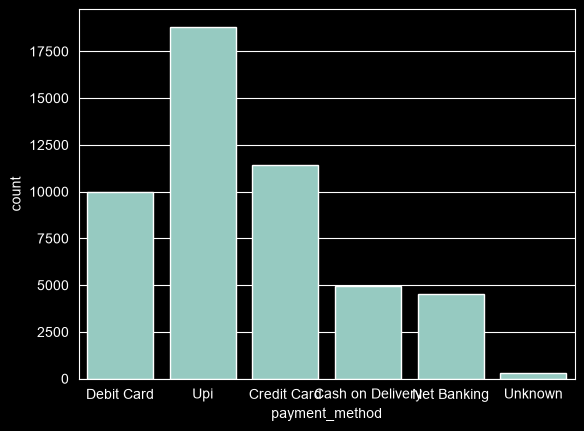

In [18]:
sns.countplot(x='payment_method', data=df)

### Payment Method Distribution Insight

UPI has the highest transaction volume among the payment methods, followed by Credit Card and Debit Card.

Cash on Delivery and Net Banking account for smaller transaction volumes, while Unknown represents a small number of transactions where the original payment method was missing.

The distribution describes transaction preference but does not indicate which payment method generates the highest Sales or Profit. Financial performance should therefore be analyzed separately.

<Axes: xlabel='order_status', ylabel='count'>

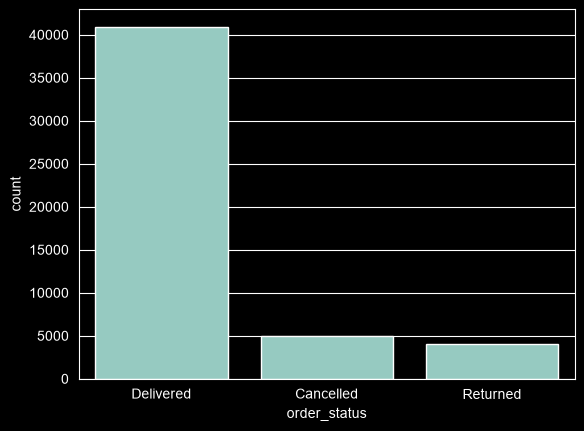

In [19]:
sns.countplot(x='order_status', data=df)

### Order Status Distribution Insight

Delivered orders account for the vast majority of transactions in the dataset, while Cancelled and Returned orders represent substantially smaller proportions.

This provides an overview of transaction outcomes, but the volume of each status alone does not indicate their financial impact. The Sales and Profit associated with each order status should be analyzed separately.

In [20]:
df.groupby('category')['sales'].sum()

category
Beauty & Personal Care    2.189057e+07
Electronics               3.022708e+08
Fashion                   5.051860e+07
Furniture                 1.445207e+08
Home & Kitchen            6.730832e+07
Name: sales, dtype: float64

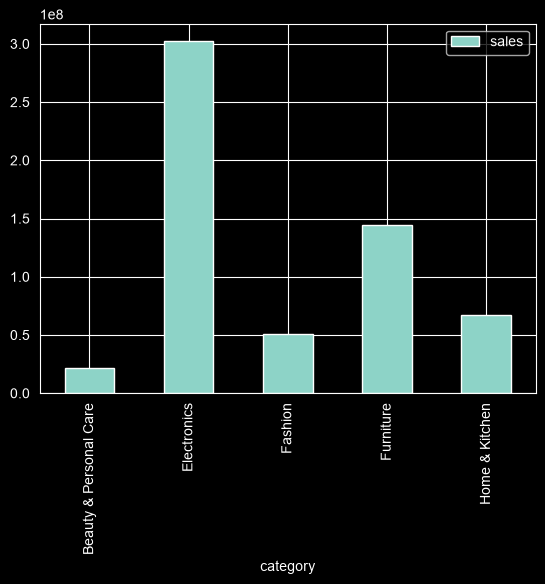

In [21]:
df.groupby('category')['sales'].sum().plot(kind='bar').legend()

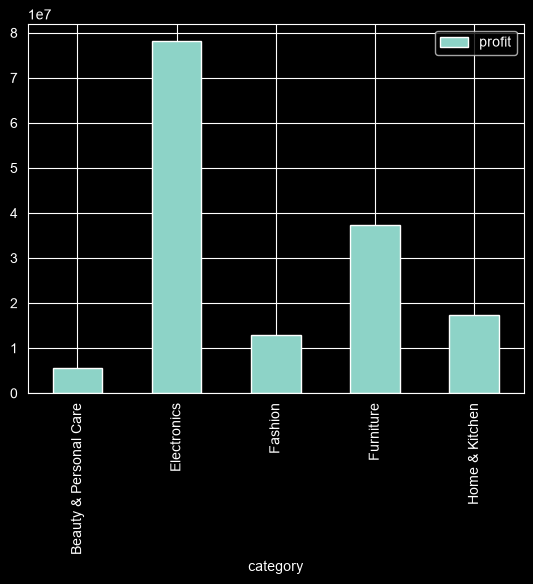

In [22]:
df.groupby('category')['profit'].sum().plot(kind='bar').legend()

##  Bivariate Analysis

In [23]:
df.groupby('category')[['sales','profit']].sum()

,sales,profit
category,,
Beauty & Personal Care,2.189057e+07,5682398.50
Electronics,3.022708e+08,78135714.02
Fashion,5.051860e+07,12965891.29
Furniture,1.445207e+08,37387129.87
Home & Kitchen,6.730832e+07,17324952.08


In [24]:
category_summary = df.groupby('category')[['sales', 'profit']].sum()

In [25]:
category_summary['profit_margin']=(category_summary['profit']/category_summary['sales'])*100
category_summary

,sales,profit,profit_margin
category,,,
Beauty & Personal Care,2.189057e+07,5682398.50,25.958207
Electronics,3.022708e+08,78135714.02,25.849574
Fashion,5.051860e+07,12965891.29,25.665580
Furniture,1.445207e+08,37387129.87,25.869748
Home & Kitchen,6.730832e+07,17324952.08,25.739688


### Category Profitability Insight

Electronics generates the highest total Sales and total Profit among all categories. However, profit margins are relatively consistent across categories, ranging from approximately 25.7% to 26.0%.

This indicates that the differences in total Profit are primarily driven by differences in Sales volume rather than major differences in profit margin.

<Axes: xlabel='category', ylabel='profit_margin'>

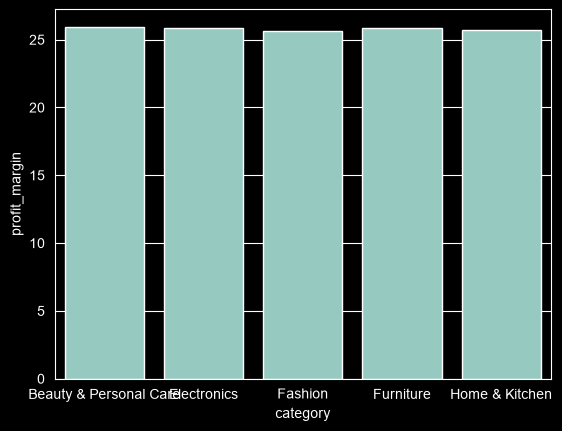

In [26]:
sns.barplot(category_summary['profit_margin'])

In [27]:
df.groupby('region')['sales'].sum()

region
East     1.123536e+08
North    1.629691e+08
South    1.676908e+08
West     1.434954e+08
Name: sales, dtype: float64

In [28]:
df.groupby('region')['profit'].sum()

region
East     29131077.01
North    42232756.14
South    43141503.44
West     36990749.17
Name: profit, dtype: float64

In [29]:
region_summary=df.groupby('region')[['sales','profit']].sum()

In [30]:
region_summary['profit_margin']=(region_summary['profit']/region_summary['sales'])*100
region_summary

,sales,profit,profit_margin
region,,,
East,1.123536e+08,29131077.01,25.928027
North,1.629691e+08,42232756.14,25.914573
South,1.676908e+08,43141503.44,25.726823
West,1.434954e+08,36990749.17,25.778346


### Regional Profitability Insight

The South region generates the highest total Sales and Profit, while the East region generates the lowest.

However, regional profit margins are relatively consistent, ranging from approximately 25.7% to 25.9%. This suggests that differences in total Profit are primarily driven by differences in Sales volume rather than substantial differences in profitability rates.

<Axes: xlabel='region'>

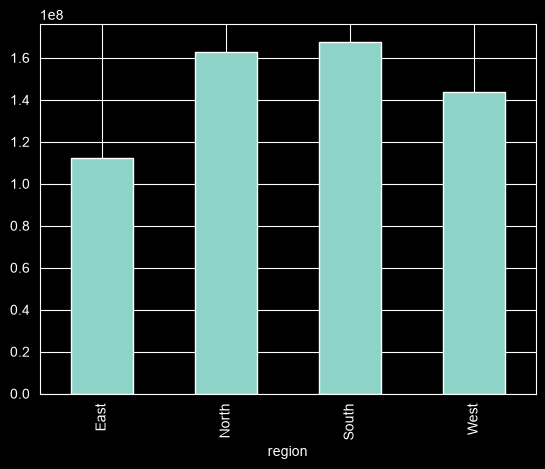

In [31]:
region_summary['sales'].plot(kind='bar')

### Regional Sales Insight

The South region generates the highest total Sales, followed closely by the North region. The West region ranks third, while the East region records the lowest total Sales.

The regional Sales pattern is broadly consistent with transaction volume, suggesting that differences in order volume are an important contributor to regional Sales performance.

In [32]:
df.groupby('sales_channel')['sales'].sum()

sales_channel
Online    3.679139e+08
Store     2.185950e+08
Name: sales, dtype: float64

In [33]:
df.groupby('sales_channel')[['sales','profit']].sum()

,sales,profit
sales_channel,,
Online,3.679139e+08,94851503.55
Store,2.185950e+08,56644582.21


In [34]:
channel_summary=df.groupby('sales_channel')[['sales','profit']].sum()

In [35]:
channel_summary['profit_margin']=(channel_summary['profit']/channel_summary['sales'])*100
channel_summary

,sales,profit,profit_margin
sales_channel,,,
Online,3.679139e+08,94851503.55,25.780894
Store,2.185950e+08,56644582.21,25.913027


### Sales Channel Profitability Insight

The Online channel generates higher total Sales and total Profit than the Store channel. However, profit margins are very similar, at approximately 25.8% for Online and 25.9% for Store.

This suggests that the higher absolute Profit generated by Online is primarily associated with its higher Sales volume rather than a substantial difference in profitability rate.

In [36]:
df.groupby('sales_channel').size()

sales_channel
Online    31182
Store     18793
dtype: int64

In [37]:
channel_summary['orders'] = df.groupby('sales_channel').size()
channel_summary

,sales,profit,profit_margin,orders
sales_channel,,,,
Online,3.679139e+08,94851503.55,25.780894,31182
Store,2.185950e+08,56644582.21,25.913027,18793


In [38]:
channel_summary['aov'] = channel_summary['sales'] / channel_summary['orders']
channel_summary

,sales,profit,profit_margin,orders,aov
sales_channel,,,,,
Online,3.679139e+08,94851503.55,25.780894,31182,11798.920535
Store,2.185950e+08,56644582.21,25.913027,18793,11631.724802


### Average Order Value (AOV) Insight

The Online channel has a slightly higher Average Order Value (₹11,798.92) compared with the Store channel (₹11,631.72).

However, the difference in AOV is relatively small. Therefore, the higher total Sales generated by the Online channel is primarily associated with its larger transaction volume rather than a substantially higher value per order.

In [39]:
df.groupby('discount')['profit'].mean()

discount
0.00    4312.070181
0.05    3595.915023
0.10    2955.721340
0.15    2343.407302
0.20    1742.481307
0.25    1068.447861
Name: profit, dtype: float64

In [40]:
df.groupby('discount')['sales'].mean()

discount
0.00    13258.981269
0.05    12105.300617
0.10    11636.894355
0.15    10996.479043
0.20    10586.559166
0.25     9747.544866
Name: sales, dtype: float64

### Discount vs Profit and Sales Insight

Average Sales and Average Profit both decrease as the discount level increases.

Average Profit declines from approximately ₹4,312 at 0% discount to ₹1,068 at 25% discount, while Average Sales declines from approximately ₹13,259 to ₹9,748.

This indicates a strong negative association between discount level and transaction-level Sales and Profit in the dataset. However, this analysis shows association rather than causation, as other factors such as product mix and quantity may also influence the results.

In [41]:
import matplotlib.pyplot as plt

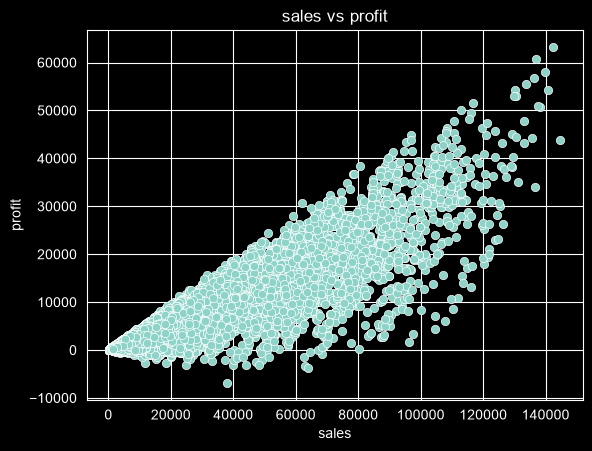

In [42]:
sns.scatterplot(data=df,x='sales',y='profit')
plt.title('sales vs profit')
plt.xlabel('sales')
plt.ylabel('profit')
plt.show()

### Sales vs Profit Insight

The scatter plot shows a strong positive relationship between Sales and Profit. Transactions with higher Sales generally tend to generate higher Profit.

The plot also shows a small number of negative-profit transactions, indicating cases where transaction costs exceed Sales.

However, Sales and Profit are directly related through the business formula Profit = Sales − Cost. Therefore, the observed relationship represents association rather than evidence that higher Sales independently cause higher Profit.

In [43]:
df['order_date']=pd.to_datetime(df['order_date'])

In [44]:
monthly_sales=df.groupby(df['order_date'].dt.to_period('M'))['sales'].sum()
monthly_sales

order_date
2024-01    25703744.39
2024-02    24369962.37
2024-03    24336281.84
2024-04    24214237.29
2024-05    23907830.44
2024-06    23993606.03
2024-07    24255166.99
2024-08    25398282.49
2024-09    23580505.07
2024-10    25377573.74
2024-11    23320719.14
2024-12    26410827.87
2025-01    24830907.31
2025-02    24351643.04
2025-03    23882849.39
2025-04    23815786.51
2025-05    24451480.53
2025-06    23906784.20
2025-07    23615278.68
2025-08    25363706.12
2025-09    23642855.63
2025-10    25125572.53
2025-11    24680887.12
2025-12    23972455.60
Freq: M, Name: sales, dtype: float64

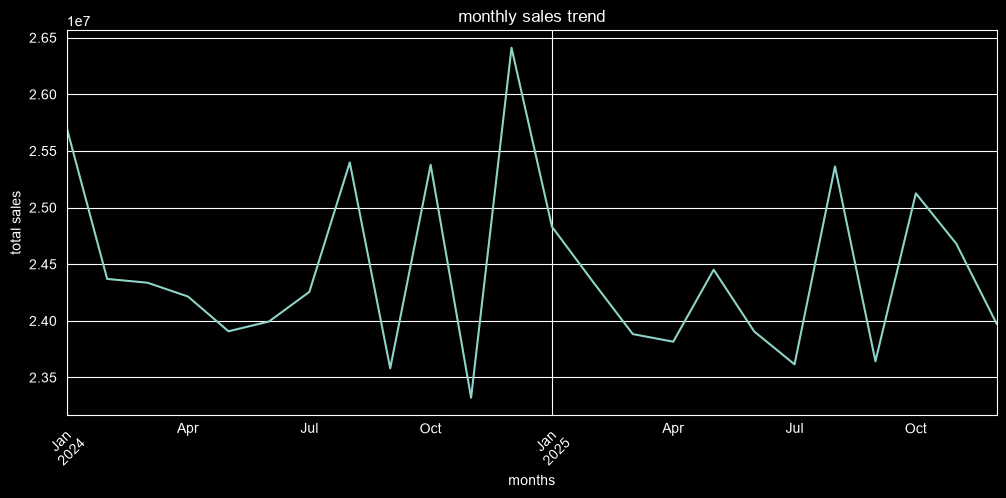

In [45]:
monthly_sales.plot(kind='line',figsize=(12,5))
plt.title('monthly sales trend')
plt.xlabel('months')
plt.ylabel('total sales')
plt.xticks(rotation=45)
plt.show()

In [46]:
highest_month = monthly_sales.idxmax()
highest_sales = monthly_sales.max()

lowest_month = monthly_sales.idxmin()
lowest_sales = monthly_sales.min()

highest_month, highest_sales, lowest_month, lowest_sales

(Period('2024-12', 'M'),
 np.float64(26410827.87),
 Period('2024-11', 'M'),
 np.float64(23320719.14))

### Monthly Sales Trend Insight

Monthly Sales remained relatively stable across the 2024–2025 period, with noticeable month-to-month fluctuations but no clear long-term upward or downward trend.

The highest monthly Sales occurred in December 2024 at approximately ₹26.41 million, while the lowest occurred in November 2024 at approximately ₹23.32 million.

The fluctuations suggest that monthly Sales vary over time, but the dataset does not show a consistent sustained growth or decline pattern.

In [47]:
df.groupby('order_status')['sales'].sum()

order_status
Cancelled    6.023952e+07
Delivered    4.804103e+08
Returned     4.585917e+07
Name: sales, dtype: float64

In [48]:
df.groupby('order_status')['profit'].sum()

order_status
Cancelled    1.577741e+07
Delivered    1.240902e+08
Returned     1.162852e+07
Name: profit, dtype: float64

In [49]:
df.groupby('order_status').size()

order_status
Cancelled     4988
Delivered    40924
Returned      4063
dtype: int64

In [50]:
status_summary=df.groupby('order_status').agg(
    orders=('order_status','size'),
    sales=('sales','sum'),
    profit=('profit','sum')
)
status_summary['avg_sales']=(status_summary['sales'] / status_summary['orders'])
status_summary['avg_profit']=(status_summary['profit'] / status_summary['orders'])
status_summary

,orders,sales,profit,avg_sales,avg_profit
order_status,,,,,
Cancelled,4988,6.023952e+07,1.577741e+07,12076.887586,3163.072897
Delivered,40924,4.804103e+08,1.240902e+08,11739.083589,3032.209862
Returned,4063,4.585917e+07,1.162852e+07,11287.022456,2862.053101


### Order Status Financial Impact Insight

Delivered orders represent the majority of transactions and contribute the highest total Sales and Profit.

Returned orders have the lowest average Sales and average Profit per transaction among the three order statuses. Cancelled orders show slightly higher average Sales and Profit than Delivered orders in this dataset.

However, Cancelled and Returned transactions contain positive Sales and Profit values. Therefore, these financial values should not automatically be interpreted as realized revenue or realized profit without additional business rules defining how cancellations and returns are accounted for.

In [51]:
numeric_cols=[
    'quantity',
    'unit_price',
    'discount',
    'sales',
    'cost',
    'profit'
]
correlation=df[numeric_cols].corr()
correlation

,quantity,unit_price,discount,sales,cost,profit
quantity,1.000000,0.008726,0.010404,0.394665,0.394011,0.349772
unit_price,0.008726,1.000000,-0.004020,0.781382,0.778094,0.697570
discount,0.010404,-0.004020,1.000000,-0.056135,-0.002000,-0.187219
sales,0.394665,0.781382,-0.056135,1.000000,0.987262,0.914438
cost,0.394011,0.778094,-0.002000,0.987262,1.000000,0.838397
profit,0.349772,0.697570,-0.187219,0.914438,0.838397,1.000000


### Correlation Analysis Insight

The correlation analysis shows a very strong positive relationship between Sales and Cost (0.987) and a strong positive relationship between Sales and Profit (0.914).

Unit Price also shows a strong positive relationship with Sales (0.781) and a moderate-to-strong positive relationship with Profit (0.698). Quantity has a moderate positive relationship with Sales (0.395) and Profit (0.350).

Discount has a weak negative relationship with Profit (-0.187) and a very weak negative relationship with Sales (-0.056), which is consistent with the earlier discount analysis.

Correlation indicates the strength and direction of linear association between variables; it does not establish causation.

In [52]:
category_channel_sales=pd.pivot_table(
    df,
    values='sales',
    index='category',
    columns='sales_channel',
    aggfunc='sum'
)
category_channel_sales

sales_channel,Online,Store
category,,
Beauty & Personal Care,1.363338e+07,8.257189e+06
Electronics,1.902855e+08,1.119853e+08
Fashion,3.143560e+07,1.908300e+07
Furniture,9.090640e+07,5.361425e+07
Home & Kitchen,4.165305e+07,2.565527e+07


### Category and Sales Channel Insight

The Online channel generates higher Sales than the Store channel across every product category.

Electronics is the highest-Sales category in both Online and Store channels, followed by Furniture. Beauty & Personal Care has the lowest Sales contribution across both channels.

The consistent Online performance across all categories indicates that the higher overall Sales of the Online channel are not driven by a single product category, but are observed across the complete category portfolio.

##  Business Insights

1. **Category Performance:** Electronics generated the highest total Sales and Profit among all categories, making it the largest contributor to overall business performance.

2. **Sales Channel Performance:** Online generated higher Sales than Store, largely associated with its higher transaction volume.

3. **Discount and Profitability:** Average Profit decreased as the discount level increased. This shows an association rather than proving that higher discounts directly cause lower Profit.

4. **Monthly Sales:** Monthly Sales fluctuated across the 2024–2025 period. December 2024 recorded the highest monthly Sales, while November 2024 recorded the lowest.

5. **Regional Performance:** South recorded the highest Sales, while East recorded the lowest Sales among the four regions.

6. **Order Status:** Cancelled orders were higher in number than Returned orders. However, cancellations and returns require additional business rules before their recorded Sales and Profit can be treated as realized financial values.

# Business Recommendations

- **Strengthen Electronics Performance:** Prioritize high-performing Electronics products, maintain adequate inventory, and identify opportunities to expand successful product lines.

- **Investigate Regional Performance:** Analyze differences in customer demand, product preferences, and sales coverage across regions, particularly between the highest- and lowest-performing regions.

- **Optimize the Online Channel:** Continue evaluating opportunities in the Online channel and investigate the factors contributing to its higher transaction volume and overall Sales.

- **Review Discount Strategy:** Evaluate the profitability of different discount levels and consider targeted discount strategies instead of relying on higher discounts broadly.

- **Monitor Returns and Cancellations:** Track Returned and Cancelled orders regularly and investigate their underlying causes to identify opportunities for reducing avoidable losses.

- **Improve Financial Data Quality:** Implement stronger validation rules for Sales, Cost, Profit, Quantity, and Discount during data ingestion to prevent inconsistent financial records.